In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

In [2]:
data = pd.read_csv(
    "../data/processed/creditguard_engineered.csv"
)
print("Dataset loaded:", data.shape)

Dataset loaded: (500, 28)


In [3]:
selected_features = [
    "Income",
    "Credit_Score",
    "Credit_Utilization",
    "Missed_Payments",
    "Loan_Balance",
    "Debt_to_Income_Ratio",
    "Account_Tenure",
    "On_Time_Count",
    "Late_Count",
    "Missed_Count",
    "Payment_Issue_Count",
    "Payment_Issue_Rate",
    "Missed_Payment_Rate",
    "On_Time_Rate",
    "Average_Payment_Status"
]

X = data[selected_features].copy()
y = data["Delinquent_Account"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [4]:
logistic_model = joblib.load(
    "../models/logistic_regression.pkl"
)
print("Model loaded successfully!")

Model loaded successfully!


In [5]:
probabilities = logistic_model.predict_proba(X_test)[:, 1]
risk_data = data.loc[X_test.index].copy()
risk_data["Predicted_Probability"] = probabilities
risk_data["Actual_Delinquency"] = y_test
risk_data.head()

,Customer_ID,Age,Income,Credit_Score,Credit_Utilization,Missed_Payments,Delinquent_Account,Loan_Balance,Debt_to_Income_Ratio,Employment_Status,Account_Tenure,Credit_Card_Type,Location,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6,On_Time_Count,Late_Count,Missed_Count,Payment_Records_Available,Payment_Issue_Count,Payment_Issue_Rate,Missed_Payment_Rate,On_Time_Rate,Average_Payment_Status,Predicted_Probability,Actual_Delinquency
57,CUST0058,43,107193.0,843.0,0.362736,0,0,70793.0,0.357470,emp,12,Student,Chicago,2,2,2,2,1,0,1,1,4,6,5,0.833333,0.666667,0.166667,1.500000,0.505142,0
413,CUST0414,52,109074.0,401.0,0.397534,0,0,61210.0,0.376581,retired,6,Gold,Chicago,1,2,0,0,2,2,2,1,3,6,4,0.666667,0.500000,0.333333,1.166667,0.537499,0
487,CUST0488,42,188420.0,550.0,0.384149,1,0,86846.0,0.420648,unemployed,18,Platinum,New York,0,2,1,2,2,0,2,1,3,6,4,0.666667,0.500000,0.333333,1.166667,0.533353,0
416,CUST0417,41,126888.0,793.0,0.337757,6,0,63412.0,0.337000,unemployed,1,Student,Phoenix,1,0,0,1,2,1,2,3,1,6,4,0.666667,0.166667,0.333333,0.833333,0.522045,0
25,CUST0026,19,193998.0,515.0,0.255552,5,0,NaN,0.259893,emp,12,Gold,Phoenix,1,2,0,1,2,0,2,2,2,6,4,0.666667,0.333333,0.333333,1.000000,0.460560,0


In [6]:
def assign_risk(probability):

    if probability < 0.30:
        return "Low"

    elif probability < 0.60:
        return "Medium"

    else:
        return "High"


risk_data["Risk_Category"] = (
    risk_data["Predicted_Probability"]
    .apply(assign_risk)
)
risk_data[
    ["Predicted_Probability", "Risk_Category"]
].head(10)

,Predicted_Probability,Risk_Category
57,0.505142,Medium
413,0.537499,Medium
487,0.533353,Medium
416,0.522045,Medium
25,0.460560,Medium
320,0.517806,Medium
327,0.399380,Medium
101,0.492732,Medium
62,0.597143,Medium
92,0.378727,Medium


In [7]:
risk_distribution = (
    risk_data["Risk_Category"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
)

print(risk_distribution)

Risk_Category
Low        0
Medium    88
High      12
Name: count, dtype: int64


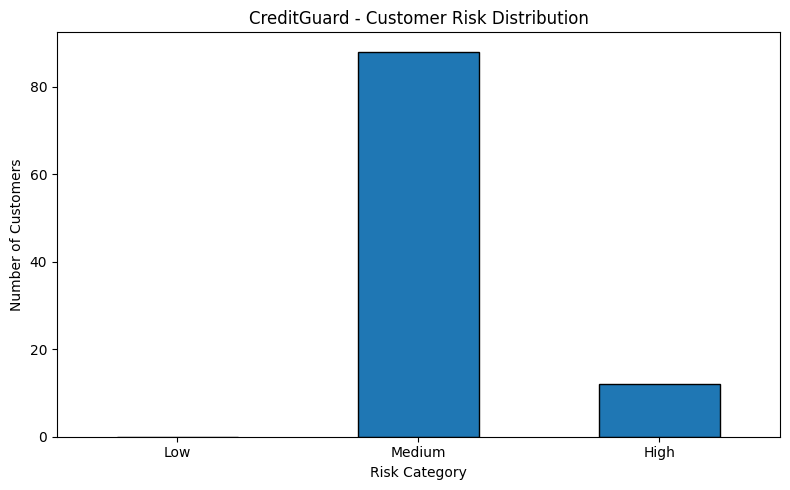

In [8]:
plt.figure(figsize=(8, 5))
risk_distribution.plot(
    kind="bar",
    edgecolor="black"
)
plt.title("CreditGuard - Customer Risk Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [9]:
risk_analysis = pd.crosstab(
    risk_data["Risk_Category"],
    risk_data["Actual_Delinquency"],
    normalize="index"
) * 100
risk_analysis.columns = [
    "Non_Delinquent_Percentage",
    "Delinquent_Percentage"
]
risk_analysis.round(2)

,Non_Delinquent_Percentage,Delinquent_Percentage
Risk_Category,,
High,83.33,16.67
Medium,84.09,15.91


In [10]:
card_risk = pd.crosstab(
    risk_data["Credit_Card_Type"],
    risk_data["Risk_Category"]
)

card_risk

Risk_Category,High,Medium
Credit_Card_Type,,
Business,7,18
Gold,2,25
Platinum,1,9
Standard,0,17
Student,2,19


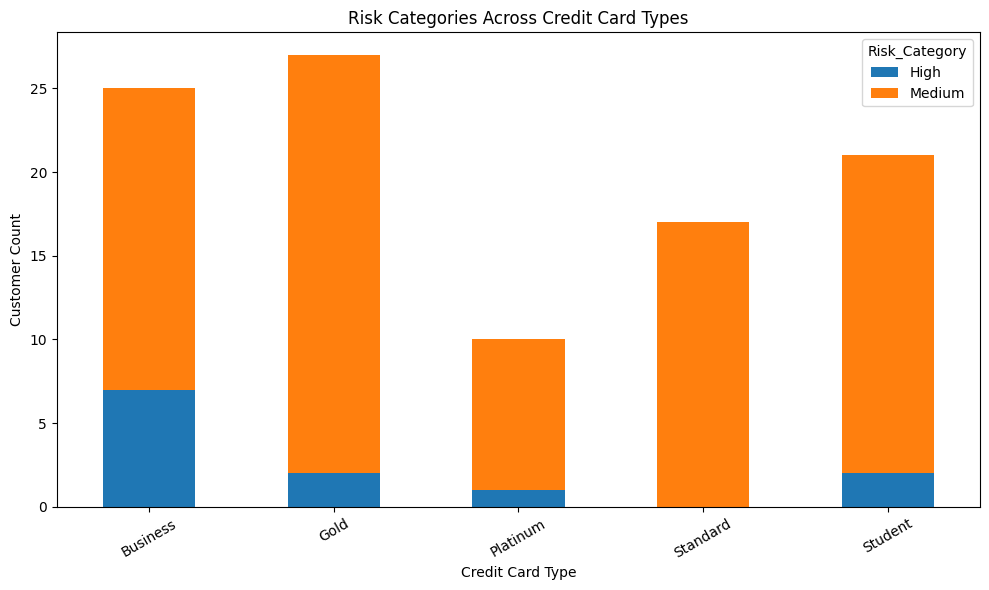

In [11]:
card_risk.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Risk Categories Across Credit Card Types")
plt.xlabel("Credit Card Type")
plt.ylabel("Customer Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [12]:
employment_risk = pd.crosstab(
    risk_data["Employment_Status"],
    risk_data["Risk_Category"]
)

employment_risk

Risk_Category,High,Medium
Employment_Status,,
emp,1,13
employed,5,23
retired,0,18
self-employed,3,13
unemployed,3,21


In [13]:
behaviour_features = [
    "On_Time_Count",
    "Late_Count",
    "Missed_Count",
    "Payment_Issue_Rate",
    "Missed_Payment_Rate"
]

behaviour_analysis = risk_data.groupby(
    "Risk_Category"
)[behaviour_features].mean()

behaviour_analysis.round(3)

,On_Time_Count,Late_Count,Missed_Count,Payment_Issue_Rate,Missed_Payment_Rate
Risk_Category,,,,,
High,2.667,2.000,1.333,0.556,0.222
Medium,1.693,1.898,2.409,0.718,0.402


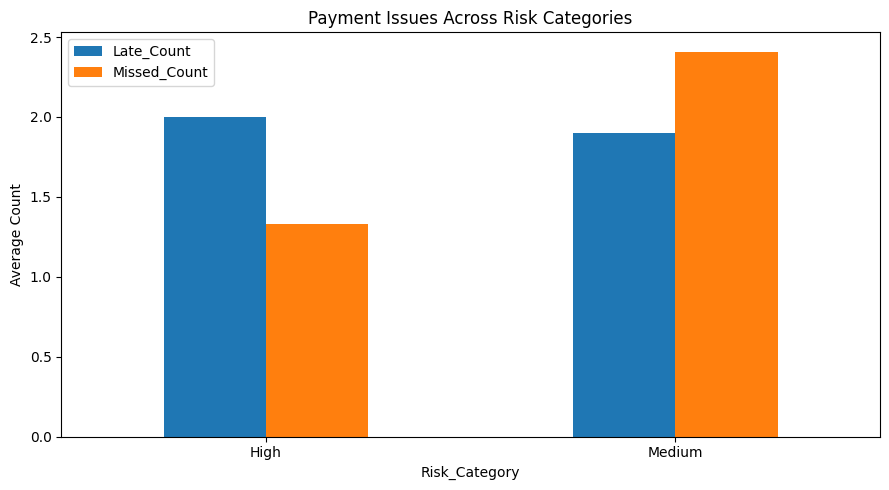

In [14]:
behaviour_analysis[
    ["Late_Count", "Missed_Count"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Payment Issues Across Risk Categories")
plt.ylabel("Average Count")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

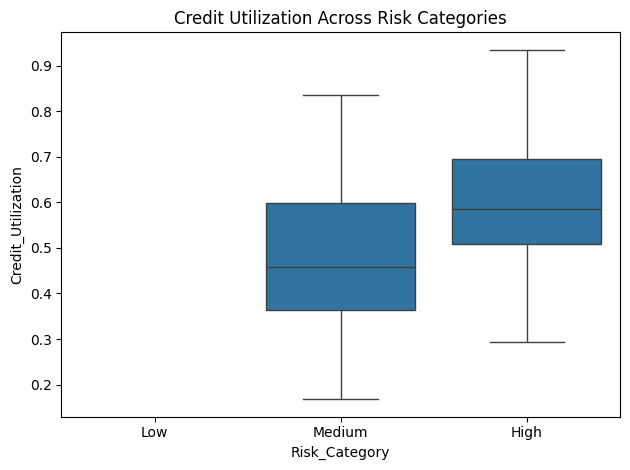

In [15]:
sns.boxplot(
    data=risk_data,
    x="Risk_Category",
    y="Credit_Utilization",
    order=["Low", "Medium", "High"]
)

plt.title("Credit Utilization Across Risk Categories")
plt.tight_layout()
plt.show()

In [17]:
intervention_mapping = {
    "Low": "Routine account monitoring and financial wellness reminders",
    "Medium": "Friendly payment reminders and optional repayment guidance",
    "High": "Priority human review and personalized repayment assistance"
}

risk_data["Suggested_Intervention"] = (
    risk_data["Risk_Category"]
    .map(intervention_mapping)
)

risk_data[
    [
        "Risk_Category",
        "Predicted_Probability",
        "Suggested_Intervention"
    ]
].head(10)

,Risk_Category,Predicted_Probability,Suggested_Intervention
57,Medium,0.505142,Friendly payment reminders and optional repaym...
413,Medium,0.537499,Friendly payment reminders and optional repaym...
487,Medium,0.533353,Friendly payment reminders and optional repaym...
416,Medium,0.522045,Friendly payment reminders and optional repaym...
25,Medium,0.460560,Friendly payment reminders and optional repaym...
320,Medium,0.517806,Friendly payment reminders and optional repaym...
327,Medium,0.399380,Friendly payment reminders and optional repaym...
101,Medium,0.492732,Friendly payment reminders and optional repaym...
62,Medium,0.597143,Friendly payment reminders and optional repaym...
92,Medium,0.378727,Friendly payment reminders and optional repaym...


In [19]:
intervention_summary = (
    risk_data["Suggested_Intervention"]
    .value_counts()
)

intervention_summary

Suggested_Intervention
Friendly payment reminders and optional repayment guidance     88
Priority human review and personalized repayment assistance    12
Name: count, dtype: int64

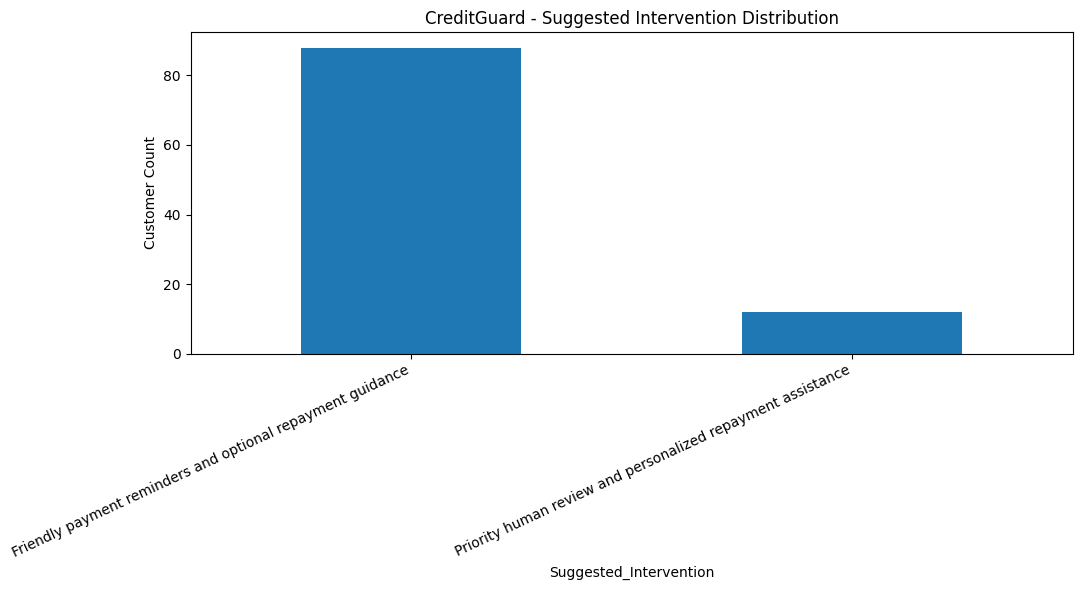

In [20]:
intervention_summary.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("CreditGuard - Suggested Intervention Distribution")
plt.ylabel("Customer Count")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [21]:
risk_intelligence = risk_data[
    [
        "Customer_ID",
        "Predicted_Probability",
        "Risk_Category",
        "Credit_Utilization",
        "Credit_Score",
        "Payment_Issue_Count",
        "Missed_Payment_Rate",
        "Suggested_Intervention"
    ]
].copy()

risk_intelligence = risk_intelligence.sort_values(
    "Predicted_Probability",
    ascending=False
)

risk_intelligence.head(15)

,Customer_ID,Predicted_Probability,Risk_Category,Credit_Utilization,Credit_Score,Payment_Issue_Count,Missed_Payment_Rate,Suggested_Intervention
151,CUST0152,0.702347,High,0.602569,524.0,3,0.166667,Priority human review and personalized repayme...
285,CUST0286,0.699186,High,0.448824,700.0,3,0.166667,Priority human review and personalized repayme...
123,CUST0124,0.678556,High,0.769656,522.0,3,0.000000,Priority human review and personalized repayme...
409,CUST0410,0.664067,High,0.292509,734.0,3,0.333333,Priority human review and personalized repayme...
2,CUST0003,0.650551,High,0.359930,500.0,5,0.333333,Priority human review and personalized repayme...
358,CUST0359,0.629291,High,0.597472,538.0,3,0.500000,Priority human review and personalized repayme...
499,CUST0500,0.620877,High,0.911370,442.0,4,0.166667,Priority human review and personalized repayme...
304,CUST0305,0.614941,High,0.572229,591.0,3,0.166667,Priority human review and personalized repayme...
256,CUST0257,0.610494,High,0.567773,524.0,2,0.166667,Priority human review and personalized repayme...
376,CUST0377,0.603013,High,0.934748,781.0,2,0.000000,Priority human review and personalized repayme...


In [22]:
total_customers = len(risk_intelligence)

high_risk = (
    risk_intelligence["Risk_Category"] == "High"
).sum()

medium_risk = (
    risk_intelligence["Risk_Category"] == "Medium"
).sum()

low_risk = (
    risk_intelligence["Risk_Category"] == "Low"
).sum()

print("CREDITGUARD RISK SUMMARY")
print("------------------------")

print("Customers analyzed:", total_customers)
print("High risk:", high_risk)
print("Medium risk:", medium_risk)
print("Low risk:", low_risk)

print(
    "High-risk percentage:",
    round(high_risk / total_customers * 100, 2),
    "%"
)

CREDITGUARD RISK SUMMARY
------------------------
Customers analyzed: 100
High risk: 12
Medium risk: 88
Low risk: 0
High-risk percentage: 12.0 %


In [23]:
print("CREDITGUARD - BUSINESS INSIGHTS")
print("=" * 40)

print(
    f"Total customers analyzed: {total_customers}"
)

print(
    f"High-risk customers identified: {high_risk}"
)

print(
    f"Medium-risk customers identified: {medium_risk}"
)

print(
    f"Low-risk customers identified: {low_risk}"
)

print("\nSuggested Business Actions:")

print("1. Provide early reminders to customers showing potential payment difficulties.")

print("2. Offer flexible repayment guidance where appropriate.")

print("3. Prioritize human review for customers assigned high risk.")

print("4. Monitor model performance and review prediction errors.")

print("5. Ensure customer treatment remains fair and consistent.")

CREDITGUARD - BUSINESS INSIGHTS
Total customers analyzed: 100
High-risk customers identified: 12
Medium-risk customers identified: 88
Low-risk customers identified: 0

Suggested Business Actions:
1. Provide early reminders to customers showing potential payment difficulties.
2. Offer flexible repayment guidance where appropriate.
3. Prioritize human review for customers assigned high risk.
4. Monitor model performance and review prediction errors.
5. Ensure customer treatment remains fair and consistent.


In [24]:
os.makedirs("../reports", exist_ok=True)

In [25]:
risk_intelligence.to_csv(
    "../reports/customer_risk_intelligence.csv",
    index=False
)

print("Risk intelligence saved!")

Risk intelligence saved!


In [26]:
risk_distribution.to_csv(
    "../reports/risk_distribution.csv"
)

print("Risk distribution saved!")

Risk distribution saved!


In [27]:
intervention_summary.to_csv(
    "../reports/intervention_summary.csv"
)

print("Intervention summary saved!")

Intervention summary saved!
